## Подбор датасетов: 
Для выполнения работы необходимо самостоятельно подобрать два различных набора данных (например, с платформы Kaggle, UCI Machine Learning Repository или встроенных датасетов scikit-learn).

### Мои датасеты 

#### Math-Students Performance Data - числовые данные
```
path = kagglehub.dataset_download("adilshamim8/math-students")
print("Path to dataset files:", path)
```

#### Billionaires Statistics Dataset - преобладание текстовых данных.
```
path = kagglehub.dataset_download("endofnight17j03/billionaires-statistics-dataset")
print("Path to dataset files:", path)
```

## Требования

### Оформление результатов и выводы

* По каждому набору данных сформулируйте краткий аналитический вывод (устно): какие особенности структуры были обнаружены, есть ли сильные корреляции, много ли аномалий.
* Оформите отчет в виде готового файла блокнота (.ipynb), содержащего как работающий код, так и текстовые комментарии (Markdown-ячейки) с интерпретацией каждого построенного графика. В случае выполнения дополнительного задания — приложите скрипт Streamlit.


### 1. Задание
Загрузить данные в DataFrame с помощью библиотеки pandas.
Вывести первые и последние 5 (10) строк таблицы для визуального ознакомления.
Программно определить размерность матрицы данных (количество строк и столбцов).
Вывести общую информацию о типах данных (.info()) и проверить соответствие типов реальным значениям.

In [3]:
import pandas as pd
import kagglehub as kg
import os
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [4]:
path1 = kg.dataset_download("adilshamim8/math-students")
print("Path 1 to dataset files:", path1)
path2 = kg.dataset_download("endofnight17j03/billionaires-statistics-dataset")
print("Path 2 to dataset files:", path2)

Path 1 to dataset files: /home/polinwq_534/.cache/kagglehub/datasets/adilshamim8/math-students/versions/1
Path 2 to dataset files: /home/polinwq_534/.cache/kagglehub/datasets/endofnight17j03/billionaires-statistics-dataset/versions/1


In [5]:
file_path1 = os.path.join(path1, os.listdir(path1)[0])
db1 = pd.read_csv(file_path1)
file_path2 = os.path.join(path2, os.listdir(path2)[0])
db2 = pd.read_csv(file_path2)

In [6]:
db1.info()

<class 'pandas.DataFrame'>
RangeIndex: 399 entries, 0 to 398
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      399 non-null    str  
 1   sex         399 non-null    str  
 2   age         399 non-null    int64
 3   address     399 non-null    str  
 4   famsize     399 non-null    str  
 5   Pstatus     399 non-null    str  
 6   Medu        399 non-null    int64
 7   Fedu        399 non-null    int64
 8   Mjob        399 non-null    str  
 9   Fjob        399 non-null    str  
 10  reason      399 non-null    str  
 11  guardian    399 non-null    str  
 12  traveltime  399 non-null    int64
 13  studytime   399 non-null    int64
 14  failures    399 non-null    int64
 15  schoolsup   399 non-null    str  
 16  famsup      399 non-null    str  
 17  paid        399 non-null    str  
 18  activities  399 non-null    str  
 19  nursery     399 non-null    str  
 20  higher      399 non-null    str  
 21  inte

In [7]:
display(db1.head(5))
display(db1.tail(5))
print("Размерность матрицы данных: " + str(db1.shape[0]) + " строк, " + str(db1.shape[1]) + "столбцов")

,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
394,MS,M,19,U,LE3,T,1,1,other,at_home,...,3,2,3,3,3,5,5,8,9,9
395,MS,M,18,U,GT3,T,4,4,teacher,services,...,5,3,2,1,2,4,0,8,7,7
396,MS,M,17,U,GT3,T,4,4,teacher,services,...,5,3,2,1,2,4,0,8,7,7
397,MS,M,19,U,GT3,T,4,4,teacher,other,...,5,3,2,1,2,4,0,8,7,7
398,MS,M,18,U,GT3,T,4,4,teacher,at_home,...,5,3,2,1,2,4,0,8,7,7


Размерность матрицы данных: 399 строк, 33столбцов



* Проверить соответствие типов реальным значениям

In [8]:
for col in db1.columns:
    is_matching = db1[col].dropna().map(type).nunique() <= 1
    print(f"{col}: {is_matching}")

school: True
sex: True
age: True
address: True
famsize: True
Pstatus: True
Medu: True
Fedu: True
Mjob: True
Fjob: True
reason: True
guardian: True
traveltime: True
studytime: True
failures: True
schoolsup: True
famsup: True
paid: True
activities: True
nursery: True
higher: True
internet: True
romantic: True
famrel: True
freetime: True
goout: True
Dalc: True
Walc: True
health: True
absences: True
G1: True
G2: True
G3: True


In [9]:
db2.info()

<class 'pandas.DataFrame'>
RangeIndex: 2640 entries, 0 to 2639
Data columns (total 35 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   rank                                        2640 non-null   int64  
 1   finalWorth                                  2640 non-null   int64  
 2   category                                    2640 non-null   str    
 3   personName                                  2640 non-null   str    
 4   age                                         2575 non-null   float64
 5   country                                     2602 non-null   str    
 6   city                                        2568 non-null   str    
 7   source                                      2640 non-null   str    
 8   industries                                  2640 non-null   str    
 9   countryOfCitizenship                        2640 non-null   str    
 10  organization           

In [10]:
display(db2.head(5))
display(db2.tail(5))
print("Размерность матрицы данных: " + str(db2.shape[0]) + " строк, " + str(db2.shape[1]) + "столбцов")

,rank,finalWorth,category,personName,age,country,city,source,industries,countryOfCitizenship,...,cpi_change_country,gdp_country,gross_tertiary_education_enrollment,gross_primary_education_enrollment_country,life_expectancy_country,tax_revenue_country_country,total_tax_rate_country,population_country,latitude_country,longitude_country
0,1,211000,Fashion & Retail,Bernard Arnault & family,74.0,France,Paris,LVMH,Fashion & Retail,France,...,1.1,"$2,715,518,274,227",65.6,102.5,82.5,24.2,60.7,67059887.0,46.227638,2.213749
1,2,180000,Automotive,Elon Musk,51.0,United States,Austin,"Tesla, SpaceX",Automotive,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,328239523.0,37.090240,-95.712891
2,3,114000,Technology,Jeff Bezos,59.0,United States,Medina,Amazon,Technology,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,328239523.0,37.090240,-95.712891
3,4,107000,Technology,Larry Ellison,78.0,United States,Lanai,Oracle,Technology,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,328239523.0,37.090240,-95.712891
4,5,106000,Finance & Investments,Warren Buffett,92.0,United States,Omaha,Berkshire Hathaway,Finance & Investments,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,328239523.0,37.090240,-95.712891


,rank,finalWorth,category,personName,age,country,city,source,industries,countryOfCitizenship,...,cpi_change_country,gdp_country,gross_tertiary_education_enrollment,gross_primary_education_enrollment_country,life_expectancy_country,tax_revenue_country_country,total_tax_rate_country,population_country,latitude_country,longitude_country
2635,2540,1000,Healthcare,Yu Rong,51.0,China,Shanghai,Health clinics,Healthcare,China,...,2.9,"$19,910,000,000,000",50.6,100.2,77.0,9.4,59.2,1.397715e+09,35.861660,104.195397
2636,2540,1000,Food & Beverage,"Richard Yuengling, Jr.",80.0,United States,Pottsville,Beer,Food & Beverage,United States,...,7.5,"$21,427,700,000,000",88.2,101.8,78.5,9.6,36.6,3.282395e+08,37.090240,-95.712891
2637,2540,1000,Manufacturing,Zhang Gongyun,60.0,China,Gaomi,Tyre manufacturing machinery,Manufacturing,China,...,2.9,"$19,910,000,000,000",50.6,100.2,77.0,9.4,59.2,1.397715e+09,35.861660,104.195397
2638,2540,1000,Real Estate,Zhang Guiping & family,71.0,China,Nanjing,Real estate,Real Estate,China,...,2.9,"$19,910,000,000,000",50.6,100.2,77.0,9.4,59.2,1.397715e+09,35.861660,104.195397
2639,2540,1000,Diversified,Inigo Zobel,66.0,Philippines,Makati,Diversified,Diversified,Philippines,...,2.5,"$376,795,508,680",35.5,107.5,71.1,14.0,43.1,1.081166e+08,12.879721,121.774017


Размерность матрицы данных: 2640 строк, 35столбцов


* Проверить соответствие типов реальным значениям

In [11]:
for col in db2.columns:
    is_matching = db2[col].dropna().map(type).nunique() <= 1
    print(f"{col}: {is_matching}")

rank: True
finalWorth: True
category: True
personName: True
age: True
country: True
city: True
source: True
industries: True
countryOfCitizenship: True
organization: True
selfMade: True
status: True
gender: True
birthDate: True
lastName: True
firstName: True
title: True
date: True
state: True
residenceStateRegion: True
birthYear: True
birthMonth: True
birthDay: True
cpi_country: True
cpi_change_country: True
gdp_country: True
gross_tertiary_education_enrollment: True
gross_primary_education_enrollment_country: True
life_expectancy_country: True
tax_revenue_country_country: True
total_tax_rate_country: True
population_country: True
latitude_country: True
longitude_country: True


### Вывод по первому заданию:

* Датасет 1 (math-students): Размерность — 399 строк и 33 столбца. Пропуски отсутствуют (все 399 значений non-null). Проверка показала полную корректность типов: числовые показатели (оценки, пропуски, возраст) сохранены как int64, а текстовые как str.

* Датасет 2 (billionaires-statistics): Размерность — 2640 строк и 35 столбцов. В данных присутствуют пропуски в ряде колонок. Автоматически определённые типы данных полностью соответствуют реальным значениям (числовые int64/float64, логические bool и текстовые str).

### 2. Задание
Получить базовые описательные статистики для численных признаков (среднее, медиана, стандартное отклонение, квантили) и категориальных признаков (количество уникальных значений, мода).
Найти количество пропущенных значений (NaN) в каждом столбце. Продемонстрировать один из способов обработки пропусков (удаление строк/столбцов или заполнение средним/медианой/модой).
Выявить наличие дубликатов в данных и удалить их при обнаружении (при наличии дубликатов).

## Math Students

In [12]:
print("Численные признаки")
display(db1.describe().T[['mean', '50%', 'std', 'min', 'max']].rename(columns=
    {'mean': 'среднее',
    '50%': 'медиана',
    'std': 'станд. отклонение',
    'min': 'минимум',
    'max': 'максимум'}))

Численные признаки


,среднее,медиана,станд. отклонение,минимум,максимум
age,16.709273,17.0,1.278225,15.0,22.0
Medu,2.761905,3.0,1.096340,0.0,4.0
Fedu,2.536341,3.0,1.092716,0.0,4.0
traveltime,1.443609,1.0,0.695429,1.0,4.0
studytime,2.035088,2.0,0.835020,1.0,4.0
failures,0.330827,0.0,0.740655,0.0,3.0
famrel,3.954887,4.0,0.898335,1.0,5.0
freetime,3.233083,3.0,0.994107,1.0,5.0
goout,3.097744,3.0,1.113178,1.0,5.0
Dalc,1.476190,1.0,0.887552,1.0,5.0


In [13]:
print("Категориальные признаки")
display(db1.describe(include=['str', 'object']).T[['unique', 'top', 'freq']].rename(columns=
    {'unique': 'уникальных значений',
    'top': 'мода (самое частое)',
    'freq': 'частота моды'}))

Категориальные признаки


,уникальных значений,мода (самое частое),частота моды
school,2,GP,349
sex,2,F,208
address,2,U,311
famsize,2,GT3,285
Pstatus,2,T,358
Mjob,5,other,141
Fjob,5,other,218
reason,4,course,147
guardian,3,mother,277
schoolsup,2,no,348


#### Поиск пропусков и дубликатов

In [14]:
print(db1.isna().sum())

school        0
sex           0
age           0
address       0
famsize       0
Pstatus       0
Medu          0
Fedu          0
Mjob          0
Fjob          0
reason        0
guardian      0
traveltime    0
studytime     0
failures      0
schoolsup     0
famsup        0
paid          0
activities    0
nursery       0
higher        0
internet      0
romantic      0
famrel        0
freetime      0
goout         0
Dalc          0
Walc          0
health        0
absences      0
G1            0
G2            0
G3            0
dtype: int64


* ПРОПУСКОВ НЕ ОБНАРУЖЕНО

In [15]:
print(db1.duplicated().sum())

0


* ДУБЛИКАТОВ НЕ ОБНАРУЖЕНО

**Вывод по датасету Math Students:**

* **Численные признаки:**
* Средний возраст учащихся составляет 16.7 лет (медиана — 17 лет) при диапазоне от 15 до 22 лет.
* Оценки за периоды (`G1`, `G2`, `G3`) демонстрируют стабильность: средние значения и медианы находятся на уровне 10.3–10.8 баллов из 20 возможных.
* Показатели пропуска занятий (`absences`) имеют значительный разброс: в среднем 5.6 пропусков, но максимальное значение достигает 75.
* Большинство учащихся демонстрируют низкий уровень потребления алкоголя в будни и чуть более высокий в выходные.


* **Категориальные признаки:**
* Большинство студентов обучаются в школе GP (349 из 399).
* В выборке преобладают девушки (`sex`: F, 208 человек).
* Подавляющее большинство планирует получать высшее образование (`higher`: yes, 379 человек) и имеет доступ к интернету дома (`internet`: yes, 329 человек). Главным опекуном чаще всего выступает мать (`guardian`: mother, 277 человек).


* **Пропуски и дубликаты:**
* Пропущенные значения в таблице полностью отсутствуют по всем 33 столбцам.
* Полные дубликаты строк в данных не обнаружены, датасет готов к дальнейшему анализу.

## Billionaires Statistics

In [16]:
print("Численные признаки")
display(db2.describe().T[['mean', '50%', 'std', 'min', 'max']].rename(columns=
    {'mean': 'среднее',
    '50%': 'медиана',
    'std': 'станд. отклонение',
    'min': 'минимум',
    'max': 'максимум'}))

Численные признаки


,среднее,медиана,станд. отклонение,минимум,максимум
rank,1.289159e+03,1.312000e+03,7.396937e+02,1.000000,2.540000e+03
finalWorth,4.623788e+03,2.300000e+03,9.834241e+03,1000.000000,2.110000e+05
age,6.514019e+01,6.500000e+01,1.325810e+01,18.000000,1.010000e+02
birthYear,1.957183e+03,1.957000e+03,1.328252e+01,1921.000000,2.004000e+03
birthMonth,5.740250e+00,6.000000e+00,3.710085e+00,1.000000,1.200000e+01
birthDay,1.209984e+01,1.100000e+01,9.918876e+00,1.000000,3.100000e+01
cpi_country,1.277552e+02,1.172400e+02,2.645295e+01,99.550000,2.885700e+02
cpi_change_country,4.364169e+00,2.900000e+00,3.623763e+00,-1.900000,5.350000e+01
gross_tertiary_education_enrollment,6.722567e+01,6.560000e+01,2.134343e+01,4.000000,1.366000e+02
gross_primary_education_enrollment_country,1.028585e+02,1.018000e+02,4.710977e+00,84.700000,1.421000e+02


In [17]:
print("Категориальные признаки")
display(db2.describe(include=['str', 'object']).T[['unique', 'top', 'freq']].rename(columns=
    {'unique': 'уникальных значений',
    'top': 'мода (самое частое)',
    'freq': 'частота моды'}))

Категориальные признаки


,уникальных значений,мода (самое частое),частота моды
category,18,Finance & Investments,372
personName,2638,Wang Yanqing & family,2
country,78,United States,754
city,741,New York,99
source,906,Real estate,151
industries,18,Finance & Investments,372
countryOfCitizenship,77,United States,735
organization,294,Meta Platforms,4
status,6,D,1223
gender,2,M,2303


#### Поиск пропусков и дубликатов

In [18]:
print(db2.isna().sum())

rank                                             0
finalWorth                                       0
category                                         0
personName                                       0
age                                             65
country                                         38
city                                            72
source                                           0
industries                                       0
countryOfCitizenship                             0
organization                                  2315
selfMade                                         0
status                                           0
gender                                           0
birthDate                                       76
lastName                                         0
firstName                                        3
title                                         2301
date                                             0
state                          

Необходимо избавиться от пропусков.

In [19]:
# 1. Удалить столбцы с большим количеством пропусков (>70%)
db2 = db2.drop(columns = ['organization', 'title', 'state', 'residenceStateRegion'])
# 2. Заполнить числовые признаки медианой
cols = [
    'age', 'birthYear', 'birthMonth', 'birthDay',
    'cpi_country', 'cpi_change_country', 'gross_tertiary_education_enrollment',
    'gross_primary_education_enrollment_country', 'life_expectancy_country',
    'tax_revenue_country_country', 'total_tax_rate_country', 
    'population_country', 'latitude_country', 'longitude_country'
]

for col in cols:
    if col in db2.columns:
        db2[col] = db2[col].fillna(db2[col].median())

# 3. Заполнить текстовые признаки 'Unknown'
cols = ['country', 'city', 'gdp_country', 'birthDate', 'firstName']

for col in cols:
    if col in db2.columns:
        db2[col] = db2[col].fillna('Unknown')
print(db2.isna().sum())
print("Размерность матрицы данных: " + str(db2.shape[0]) + " строк, " + str(db2.shape[1]) + "столбцов")

rank                                          0
finalWorth                                    0
category                                      0
personName                                    0
age                                           0
country                                       0
city                                          0
source                                        0
industries                                    0
countryOfCitizenship                          0
selfMade                                      0
status                                        0
gender                                        0
birthDate                                     0
lastName                                      0
firstName                                     0
date                                          0
birthYear                                     0
birthMonth                                    0
birthDay                                      0
cpi_country                             

* ПРОПУСКОВ НЕ ОБНАРУЖЕНО

In [20]:
print(db2.duplicated().sum())

0


* ДУБЛИКАТОВ НЕ ОБНАРУЖЕНО

**Вывод по датасету Billionaires Statistics:**

* **Численные признаки:**
* Средний возраст миллиардеров составляет около 65.1 лет (медиана — 65 лет) с диапазоном от 18 до 101 года.
* Чистый капитал имеет сильнейшую асимметрию: медианное значение составляет 2 300 млн (2.3 млрд), а среднее за счёт сверхбогатых участников — 4 623 млн ($4.62 млрд), при максимальном значении в 211 000 млн (211 млрд).
* Демографические и макроэкономические показатели отражают условия проживания: средняя продолжительность жизни в странах проживания миллиардеров составляет около 78.1 лет, а общая налоговая ставка в среднем 43.9%.


* **Категориальные признаки:**
* Доминирующей индустрией и категорией доходов является *Finance & Investments* (372 человека).
* Основная часть миллиардеров проживает и имеет гражданство в США (754 человека), а среди городов лидирует Нью-Йорк (99 человек).
* В выборке наблюдается существенный гендерный дисбаланс: преобладают мужчины (`gender`: M, 2303 человека из 2640).


* **Пропуски и дубликаты:**
* Первоначально в датасете присутствовали пропуски. Столбцы с критическим объемом отсутствующих данных (`organization`, `title`, `state`, `residenceStateRegion`) были удалены.
* Пропуски в численных переменных были успешно заполнены медианными значениями, а в категориальных — строковой заглушкой `'Unknown'`.
* Итоговая размерность очищенной матрицы составила 2640 строк и 31 столбец.
* Полные дубликаты строк в данных не обнаружены (0), датасет полностью подготовлен к дальнейшей визуализации и анализу.

### 3. Задание
С помощью библиотек matplotlib и seaborn построить графики распределения (гистограммы, графики плотности) для ключевых признаков.
Построить диаграммы размаха («ящик с усами» / boxplot) для численных переменных с целью обнаружения статистических выбросов (аномалий).
Требование к разнообразию визуализации: Студент должен продемонстрировать умение использовать различные варианты графиков для решения однотипных задач (например, сравнить распределение признака одновременно через гистограмму histplot, график плотности kdeplot и скрипичную диаграмму violinplot).

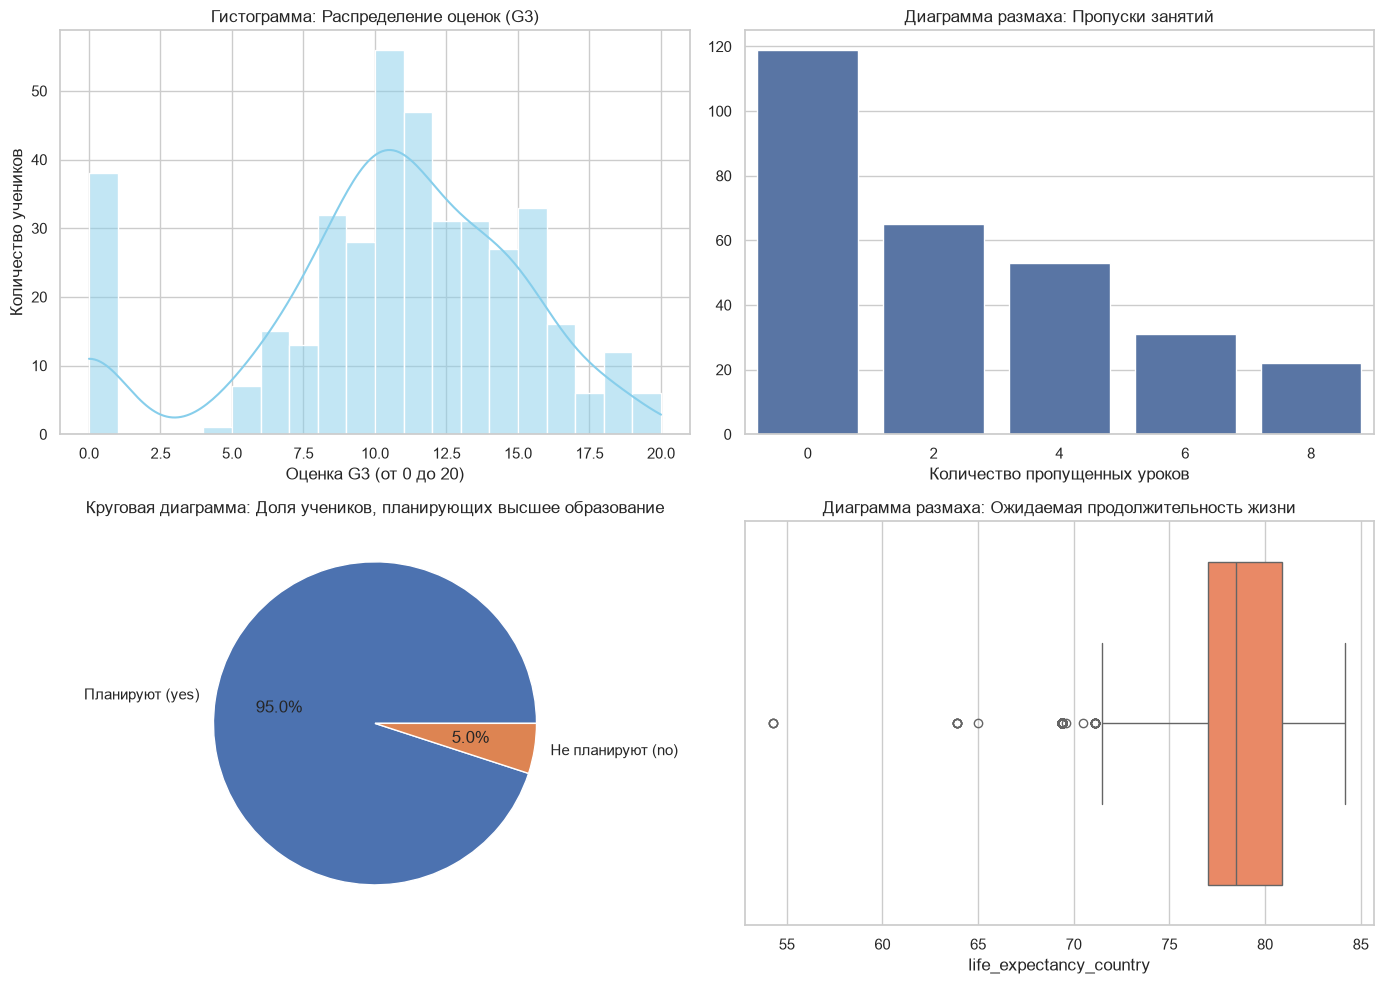

In [21]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Гистограмма и плотность для итоговой оценки (G3)
sns.histplot(db1['G3'], kde=True, ax=axes[0, 0], color='skyblue', bins=20)
axes[0, 0].set_title('Гистограмма: Распределение оценок (G3)')
axes[0, 0].set_xlabel('Оценка G3 (от 0 до 20)')
axes[0, 0].set_ylabel('Количество учеников')

axes[0, 1].set_title('Диаграмма размаха: Пропуски занятий')
axes[0, 1].set_xlabel('Количество пропущенных уроков')
abses = db1['absences'].value_counts().head(5)
sns.barplot(
    x=abses.index.astype(str), 
    y=abses.values,
    ax=axes[0, 1]
)

higher_counts = db1['higher'].value_counts()
axes[1, 0].pie(
    higher_counts, 
    labels=['Планируют (yes)', 'Не планируют (no)'], 
    autopct='%1.1f%%'
)
axes[1, 0].set_title('Круговая диаграмма: Доля учеников, планирующих высшее образование')

sns.boxplot(x=db2['life_expectancy_country'], ax=axes[1, 1], color='coral')
axes[1, 1].set_title('Диаграмма размаха: Ожидаемая продолжительность жизни')

plt.tight_layout()
plt.show()

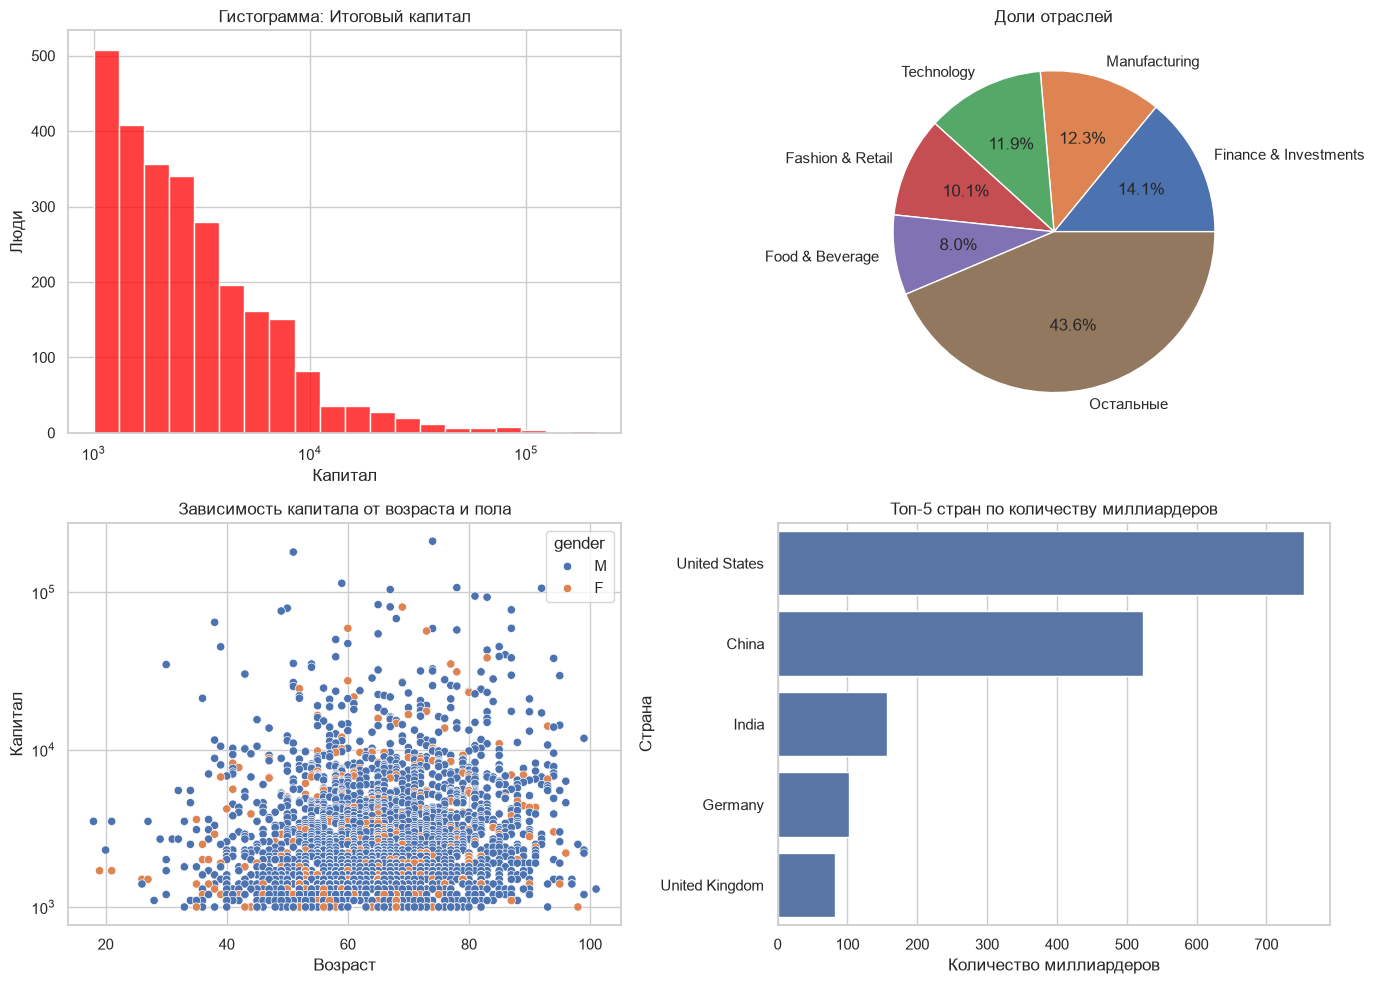

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.histplot(db2['finalWorth'], color='red', ax=axes[0, 0], kde=False, bins=20, log_scale=True)
axes[0, 0].set_title("Гистограмма: Итоговый капитал")
axes[0, 0].set_ylabel('Люди')
axes[0, 0].set_xlabel('Капитал')


def prepare_pie_data(series, top_n=5):
    counts = series.value_counts()
    top = counts.head(top_n)
    others_count = counts.iloc[top_n:].sum()
    if others_count > 0:
        top['Остальные'] = others_count
    return top

ind = prepare_pie_data(db2['industries'])
axes[0, 1].pie(
    ind, 
    labels=ind.index, 
    autopct='%1.1f%%'
)
axes[0, 1].set_title('Доли отраслей')

sns.scatterplot(
    data=db2, 
    x='age', 
    y='finalWorth', 
    hue='gender', 
    ax=axes[1, 0]
)
axes[1, 0].set_yscale('log')
axes[1, 0].set_title('Зависимость капитала от возраста и пола')
axes[1, 0].set_xlabel('Возраст')
axes[1, 0].set_ylabel('Капитал')


top_countries = db2['country'].value_counts().head(5)
sns.barplot(
    x=top_countries.values, 
    y=top_countries.index, 
    ax=axes[1, 1]
)
axes[1, 1].set_title('Топ-5 стран по количеству миллиардеров')
axes[1, 1].set_xlabel('Количество миллиардеров')
axes[1, 1].set_ylabel('Страна')


plt.tight_layout()
plt.show()

## 4. Задание
Построить матрицу корреляции для численных признаков датасета.
Визуализировать матрицу корреляции в виде тепловой карты (heatmap) с отображением коэффициентов.
Построить диаграммы рассеяния (scatterplot) или парные графики (pairplot) для пар признаков с наиболее сильной линейной зависимостью.

### Math Students

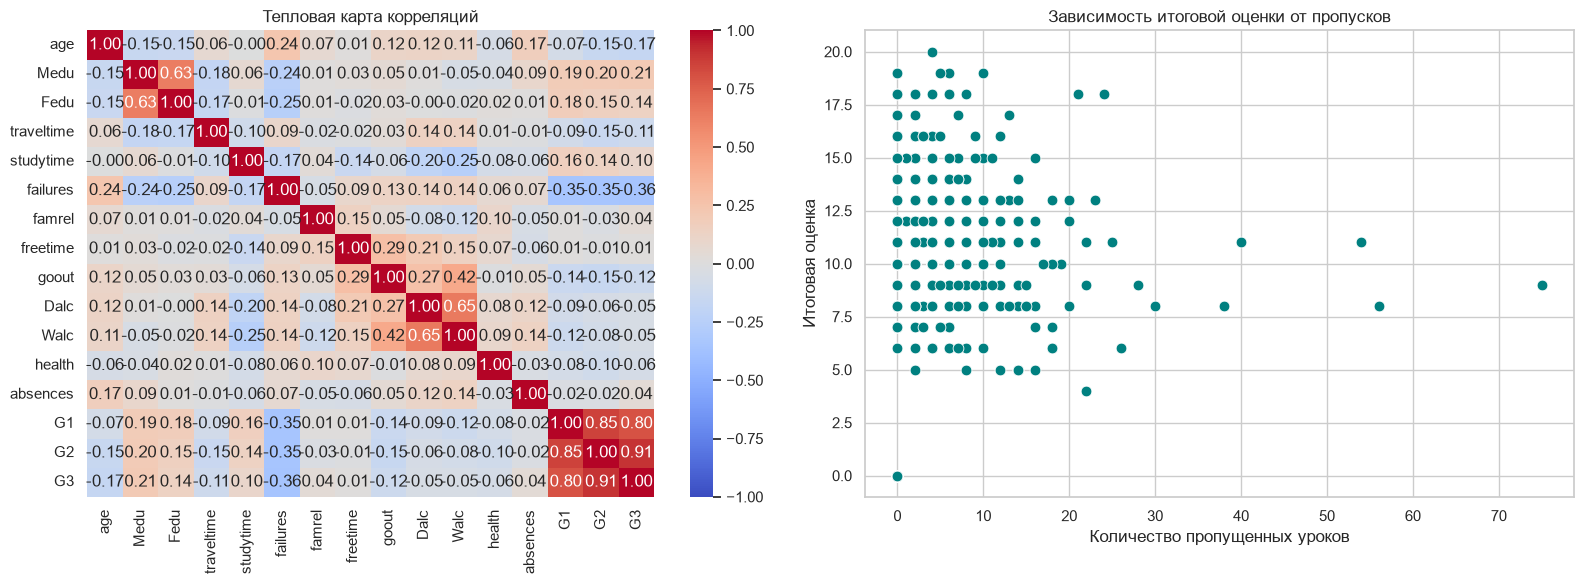

In [23]:
numeric_db1 = db1.select_dtypes(include=[np.number])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

corr_db1 = numeric_db1.corr()
sns.heatmap(
    corr_db1,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[0],
    vmin=-1,
    vmax=1,
    cbar=True,
)
axes[0].set_title("Тепловая карта корреляций")

# Pairplot для db1 (оценки и пропуски)
sns.scatterplot(
    data=db1,
    x="absences",
    y="G3",
    ax=axes[1],
    color="teal",
    s=60
)
axes[1].set_title("Зависимость итоговой оценки от пропусков")
axes[1].set_xlabel("Количество пропущенных уроков")
axes[1].set_ylabel("Итоговая оценка")

plt.tight_layout()
plt.show()

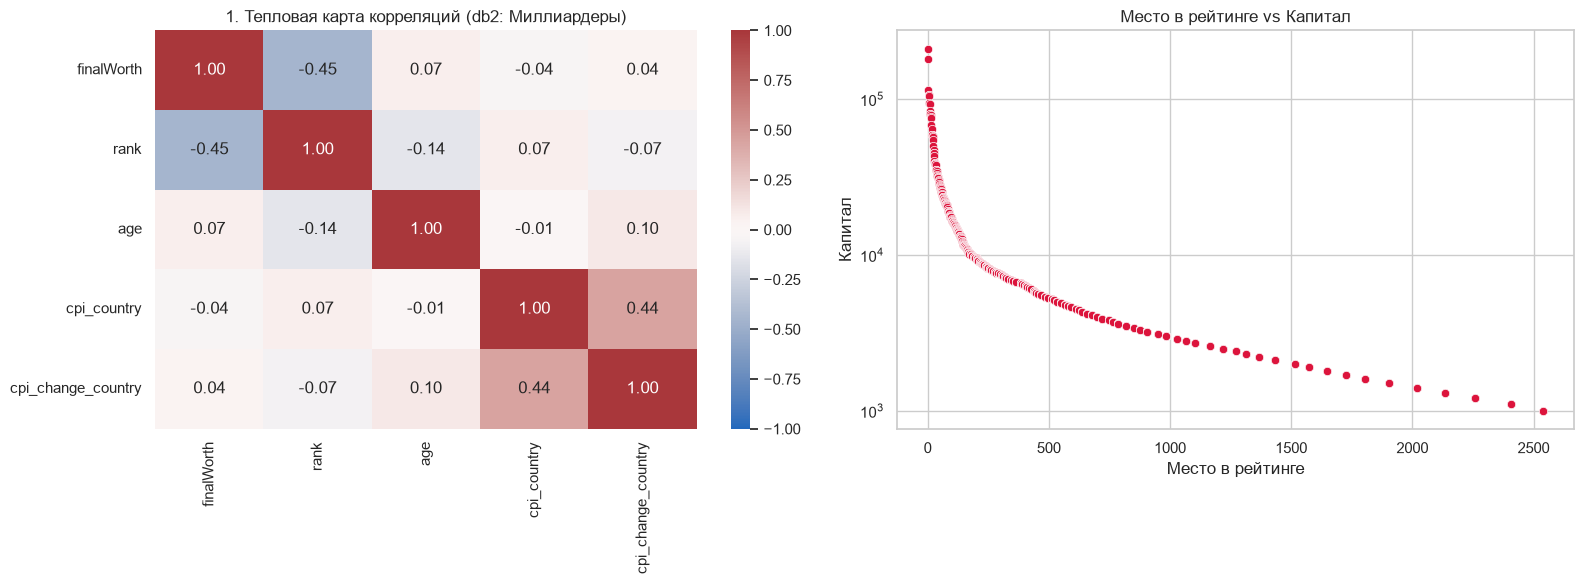

In [24]:
num_cols_db2 = ["finalWorth", "rank", "age", "cpi_country", "cpi_change_country"]
corr_db2 = db2[num_cols_db2].corr()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    corr_db2,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    ax=axes[0],
    vmin=-1,
    vmax=1,
    cbar=True
)
axes[0].set_title("1. Тепловая карта корреляций (db2: Миллиардеры)")

sns.scatterplot(
    data=db2,
    x="rank",
    y="finalWorth",
    ax=axes[1],
    color="crimson"
)
axes[1].set_yscale("log")  
axes[1].set_title("Место в рейтинге vs Капитал")
axes[1].set_xlabel("Место в рейтинге")
axes[1].set_ylabel("Капитал")

plt.tight_layout()
plt.show()

### Выводы по 4 заданию

**Датасет 1 (`db1` — Студенты)**

* **Сильнейшая взаимосвязь:** Наблюдается почти идеальная прямая линейная зависимость между оценками за прошлые периоды и итоговой оценкой ($G1$, $G2$ и $G3$ имеют корреляцию близкую к $0.85$–$0.91$). Успеваемость в течение года — главный фактор финального балла.
* **Влияние пропусков (`absences`):** Зависимость итоговой оценки от количества пропусков практически отсутствует (коэффициент корреляции близок к $0$). Как видно на `scatterplot`, отличную оценку ($15$–$20$ баллов) получают как студенты с нулем пропусков, так и те, кто пропустил $10$–$20$ уроков.

**Датасет 2 (`db2` — Миллиардеры)**

* **Сильнейшая взаимосвязь:** Наблюдается умеренная обратная связь между местом в рейтинге (`rank`) и капиталом (`finalWorth`) с коэффициентом $r = -0.45$. На `scatterplot` эта зависимость имеет явный экспоненциальный/гиперболический характер: первые места имеют колоссальный отрыв по состоянию, после чего кривая капиталов резко выполаживается.
* **Прочие факторы:** Возраст (`age`) и макроэкономические показатели страны (`cpi_country`) практически не имеют линейной связи с капиталом миллиардера (корреляция около $0$), что говорит об отсутствии прямой зависимости богатства от возраста или инфляции в стране.